In [16]:
import boto3
import pandas as pd
import io

s3 = boto3.client('s3')
bucket_name = 'dinov3-final-bucket'
paginator = s3.get_paginator('list_objects_v2')
pages = paginator.paginate(Bucket=bucket_name)

matching_keys = []
for page in pages:
    for obj in page.get('Contents', []):
        if obj['Key'].endswith('training_metrics.json'):
            matching_keys.append(obj['Key'])

if len(matching_keys) == 1:
    obj = s3.get_object(Bucket=bucket_name, Key=matching_keys[0])
    df = pd.read_json(io.BytesIO(obj['Body'].read()), lines=True)
    print(df.head())
else:
    print(f"wrong number training jsons found {matching_keys}")

   iteration   iter_time   data_time        lr    wd    mom  last_layer_lr  \
0          0  281.882294  213.461594  0.000000  0.04  0.992            0.0   
1         10   40.827419   20.806566  0.000002  0.04  0.992            0.0   
2         20   17.622326    0.779180  0.000003  0.04  0.992            0.0   
3         30   20.822727    0.020158  0.000006  0.04  0.992            0.0   
4         40   25.948832    0.023177  0.000010  0.04  0.992            0.0   

   total_loss  local_batch_size  global_batch_size  dino_local_crops_loss  \
0   18.280514               128               1024              11.110490   
1   18.230852               128               1024              11.110369   
2   18.142189               128               1024              11.110038   
3   17.948954               128               1024              11.109403   
4   17.764618               128               1024              11.108762   

   dino_local_loss_weight  dino_global_crops_loss  koleo_loss  ibot_

In [17]:
print(len(df))

1544


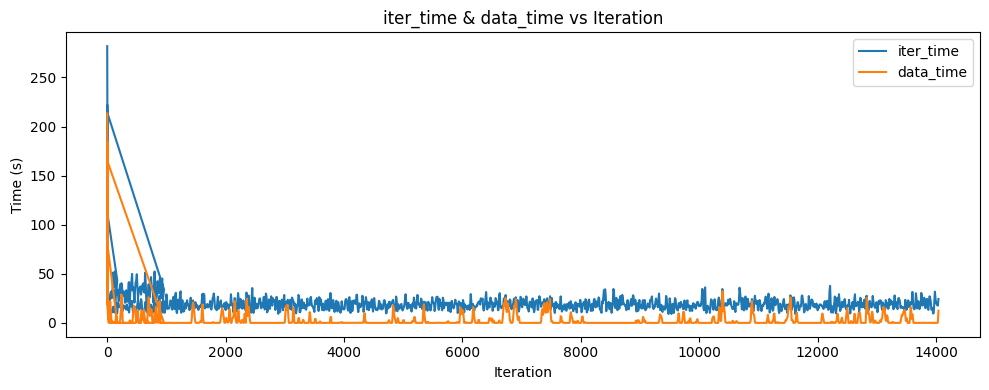

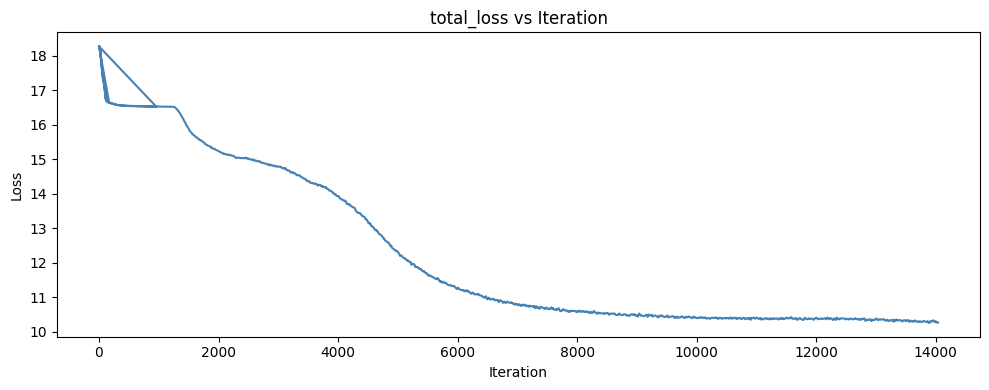

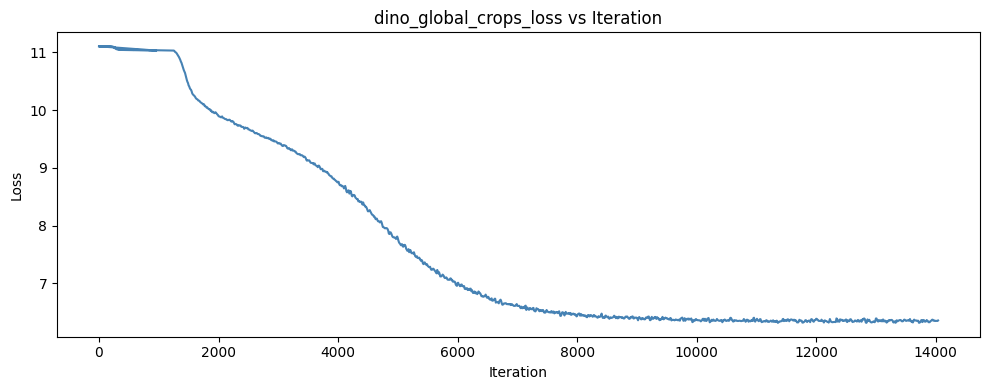

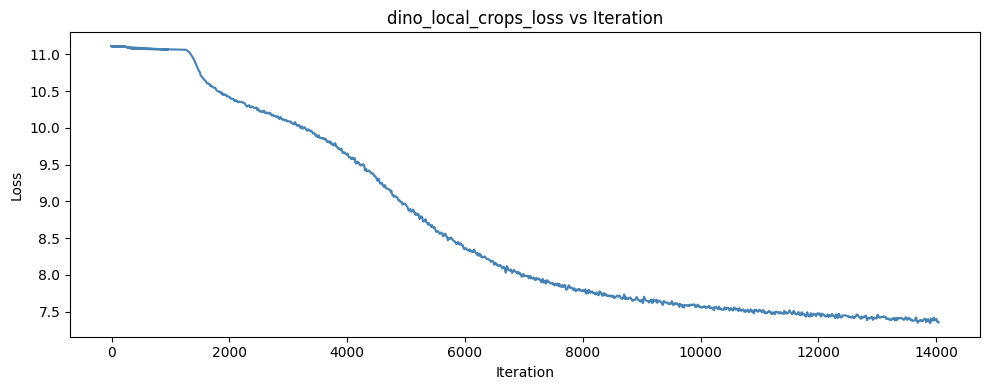

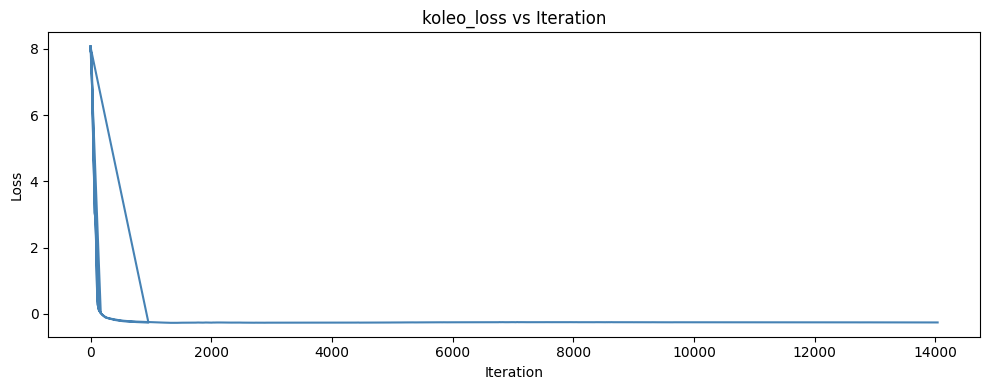

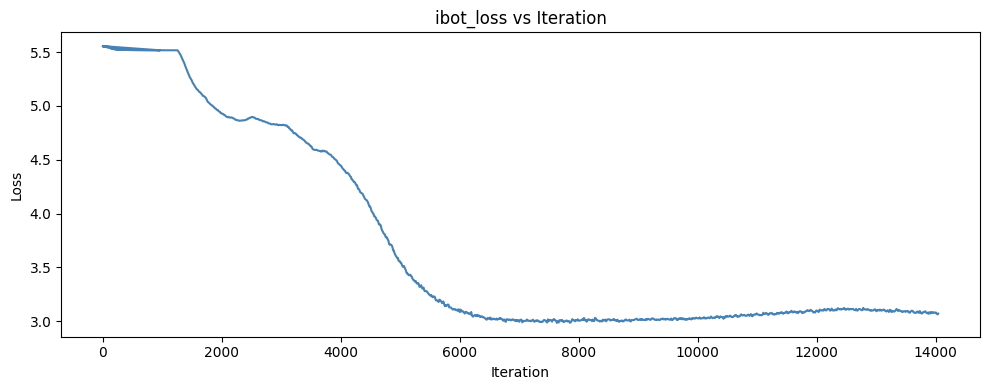

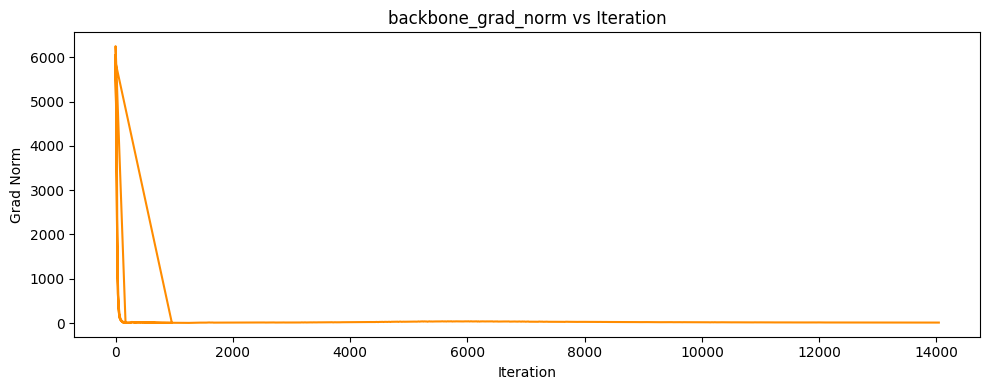

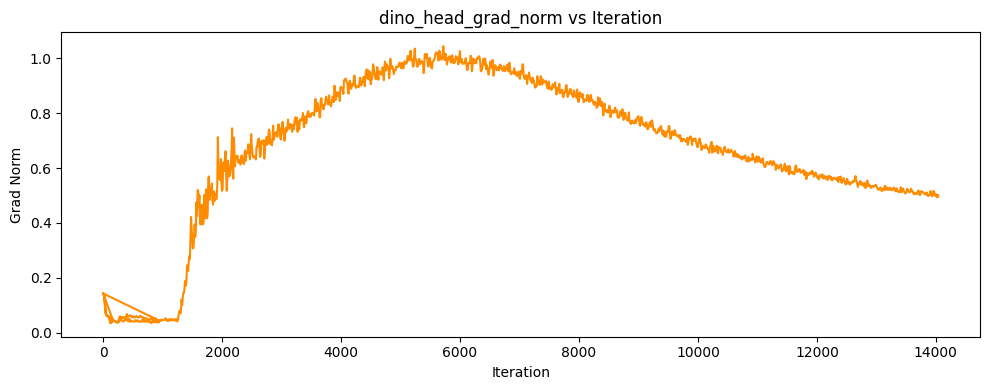

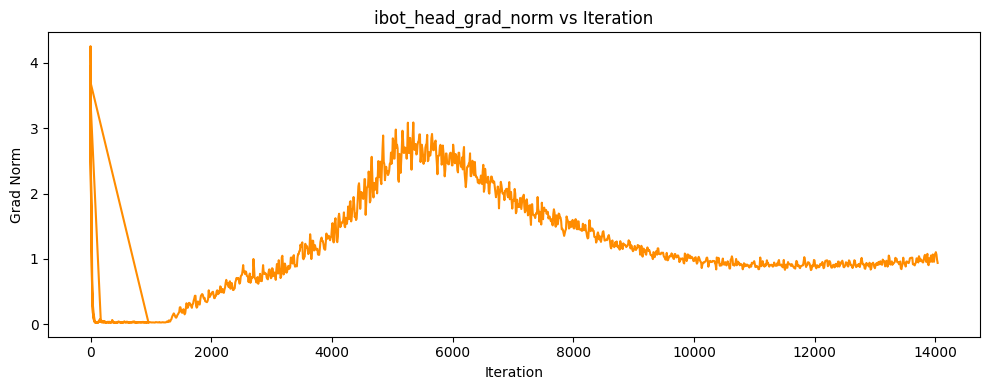

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['iteration'], df['iter_time'],  label='iter_time')
ax.plot(df['iteration'], df['data_time'],  label='data_time')
ax.set_xlabel('Iteration')
ax.set_ylabel('Time (s)')
ax.set_title('iter_time & data_time vs Iteration')
ax.legend()
plt.tight_layout()
plt.show()

loss_cols = [
    'total_loss',
    'dino_global_crops_loss',
    'dino_local_crops_loss',
    'koleo_loss',
    'ibot_loss',
]

for col in loss_cols:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(df['iteration'], df[col], color='steelblue')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Loss')
    ax.set_title(f'{col} vs Iteration')
    plt.tight_layout()
    plt.show()

grad_cols = [
    'backbone_grad_norm',
    'dino_head_grad_norm',
    'ibot_head_grad_norm',
]

for col in grad_cols:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(df['iteration'], df[col], color='darkorange')
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Grad Norm')
    ax.set_title(f'{col} vs Iteration')
    plt.tight_layout()
    plt.show()
